# Experiment 3 – Exploratory Data Analysis and Visualization using Python
**Dataset:** Food_Delivery_Customer_Churn.csv (500 records, 11 attributes)

**Aim:** Perform EDA (inspection, central tendency, dispersion, correlation) and visualize the data with Matplotlib and Seaborn.

In [1]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# Works in Google Colab (/content) and locally (CSV in the same folder)
matches = glob.glob('/content/Food_Delivery_Customer_Churn*.csv') + glob.glob('Food_Delivery_Customer_Churn*.csv')
if not matches:
    raise FileNotFoundError('Place Food_Delivery_Customer_Churn.csv next to this notebook (or upload it in Colab).')
df = pd.read_csv(matches[0])
print('Dataset loaded:', matches[0])

Dataset loaded: Food_Delivery_Customer_Churn.csv


## 1. Dataset inspection

In [2]:
print('=== FIRST 5 RECORDS ===')
print(df.head())
print('\n=== SHAPE ===')
print(df.shape)
print('\n=== DATA TYPES ===')
print(df.dtypes)

=== FIRST 5 RECORDS ===
   Age         City Subscription_Type  Orders_Per_Month  Average_Order_Value  \
0   56        Thane              Free                 2                  151   
1   46       Mumbai              Free                 8                  738   
2   32         Pune              Free                13                  793   
3   60  Navi Mumbai           Premium                13                  239   
4   25  Navi Mumbai              Free                 1                  499   

   Average_Delivery_Time  Discount_Usage Favorite_Category   Device  \
0                     36              39            Indian  Android   
1                     42              13           Chinese      Web   
2                     21              34            Indian      iOS   
3                     49              47           Mexican  Android   
4                     69              83           Burgers      iOS   

   Tenure_Months     Churn  
0              4  Retained  
1         

In [3]:
print('=== MISSING VALUES ===')
print(df.isnull().sum())
print('\n=== DUPLICATE ROWS ===', df.duplicated().sum())
print('\n=== CHURN DISTRIBUTION ===')
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True).round(3))

=== MISSING VALUES ===
Age                      0
City                     0
Subscription_Type        0
Orders_Per_Month         0
Average_Order_Value      0
Average_Delivery_Time    0
Discount_Usage           0
Favorite_Category        0
Device                   0
Tenure_Months            0
Churn                    0
dtype: int64

=== DUPLICATE ROWS === 0

=== CHURN DISTRIBUTION ===
Churn
Retained    309
Churned     191
Name: count, dtype: int64
Churn
Retained    0.618
Churned     0.382
Name: proportion, dtype: float64


In [4]:
print('=== SUMMARY STATISTICS ===')
print(df.describe().round(2))

=== SUMMARY STATISTICS ===
          Age  Orders_Per_Month  Average_Order_Value  Average_Delivery_Time  \
count  500.00            500.00               500.00                 500.00   
mean    39.51             10.56               680.92                  42.12   
std     12.37              5.72               298.67                  16.13   
min     18.00              1.00               151.00                  15.00   
25%     29.00              6.00               422.00                  28.75   
50%     41.00             11.00               671.50                  41.00   
75%     50.00             15.00               922.75                  56.00   
max     60.00             20.00              1199.00                  70.00   

       Discount_Usage  Tenure_Months  
count          500.00         500.00  
mean            48.67          24.54  
std             27.69          13.20  
min              0.00           1.00  
25%             26.00          13.00  
50%             47.00      

## 2. Central tendency

In [5]:
num_cols = ['Age','Orders_Per_Month','Average_Order_Value','Average_Delivery_Time','Discount_Usage','Tenure_Months']
print('=== CENTRAL TENDENCY ===')
ct = pd.DataFrame({'Mean': df[num_cols].mean(), 'Median': df[num_cols].median(), 'Mode': [df[c].mode()[0] for c in num_cols]})
print(ct.round(2))

=== CENTRAL TENDENCY ===
                         Mean  Median  Mode
Age                     39.51    41.0    50
Orders_Per_Month        10.56    11.0    15
Average_Order_Value    680.92   671.5   298
Average_Delivery_Time   42.12    41.0    35
Discount_Usage          48.67    47.0    18
Tenure_Months           24.54    24.0    13


## 3. Measures of dispersion

In [6]:
print('=== MEASURES OF DISPERSION ===')
disp = pd.DataFrame({
    'Std Dev': df[num_cols].std(),
    'Variance': df[num_cols].var(),
    'Range': df[num_cols].max() - df[num_cols].min(),
    'IQR': df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25)
})
print(disp.round(2))

=== MEASURES OF DISPERSION ===
                       Std Dev  Variance  Range     IQR
Age                      12.37    152.98     42   21.00
Orders_Per_Month          5.72     32.77     19    9.00
Average_Order_Value     298.67  89201.40   1048  500.75
Average_Delivery_Time    16.13    260.22     55   27.25
Discount_Usage           27.69    766.70    100   45.00
Tenure_Months            13.20    174.20     47   23.00


## 4. Correlation analysis

In [7]:
corr_matrix = df[num_cols].corr()
print('=== CORRELATION MATRIX ===')
print(corr_matrix.round(2))

=== CORRELATION MATRIX ===
                        Age  Orders_Per_Month  Average_Order_Value  \
Age                    1.00             -0.09                -0.03   
Orders_Per_Month      -0.09              1.00                 0.03   
Average_Order_Value   -0.03              0.03                 1.00   
Average_Delivery_Time  0.07              0.02                 0.05   
Discount_Usage        -0.01              0.05                 0.08   
Tenure_Months         -0.07              0.07                -0.06   

                       Average_Delivery_Time  Discount_Usage  Tenure_Months  
Age                                     0.07           -0.01          -0.07  
Orders_Per_Month                        0.02            0.05           0.07  
Average_Order_Value                     0.05            0.08          -0.06  
Average_Delivery_Time                   1.00           -0.03           0.03  
Discount_Usage                         -0.03            1.00          -0.05  
Tenure_Months 

## 5. Visualizations

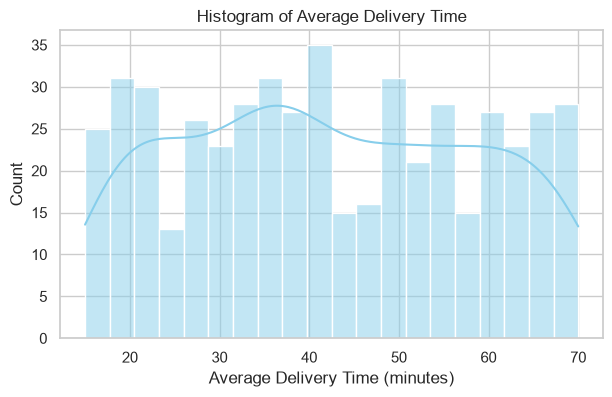

In [8]:
plt.figure(figsize=(7,4))
sns.histplot(df['Average_Delivery_Time'], bins=20, kde=True, color='skyblue')
plt.title('Histogram of Average Delivery Time')
plt.xlabel('Average Delivery Time (minutes)')
plt.show()

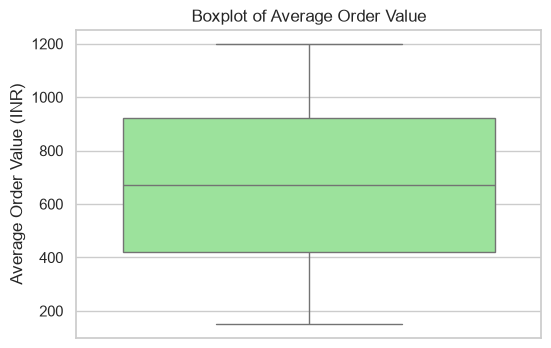

In [9]:
plt.figure(figsize=(6,4))
sns.boxplot(y=df['Average_Order_Value'], color='lightgreen')
plt.title('Boxplot of Average Order Value')
plt.ylabel('Average Order Value (INR)')
plt.show()

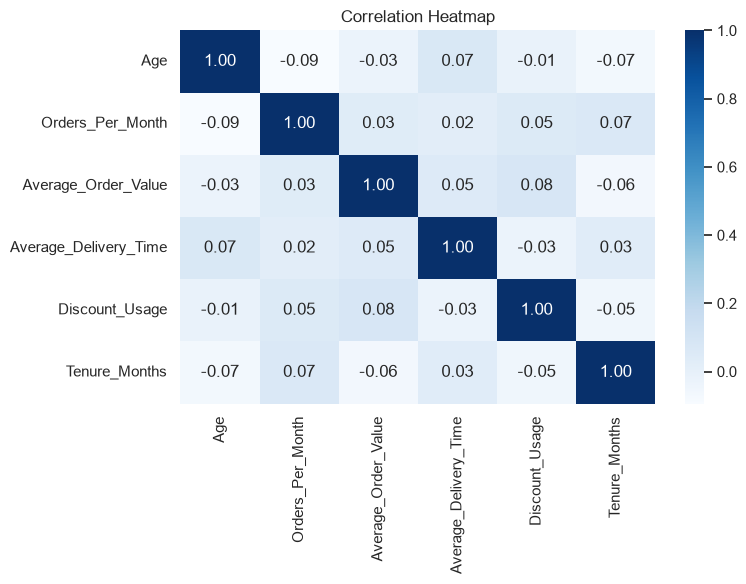

In [10]:
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

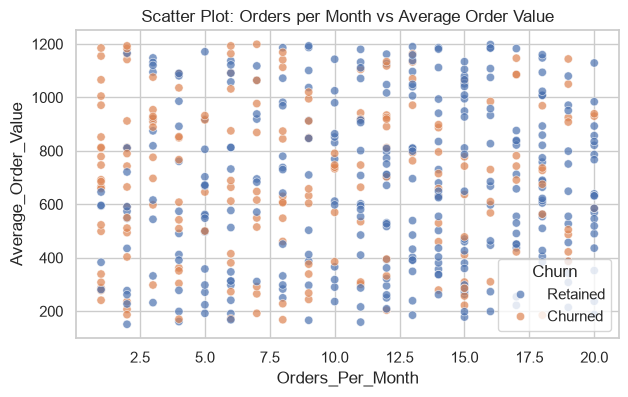

In [11]:
plt.figure(figsize=(7,4))
sns.scatterplot(data=df, x='Orders_Per_Month', y='Average_Order_Value', hue='Churn', alpha=0.7)
plt.title('Scatter Plot: Orders per Month vs Average Order Value')
plt.show()

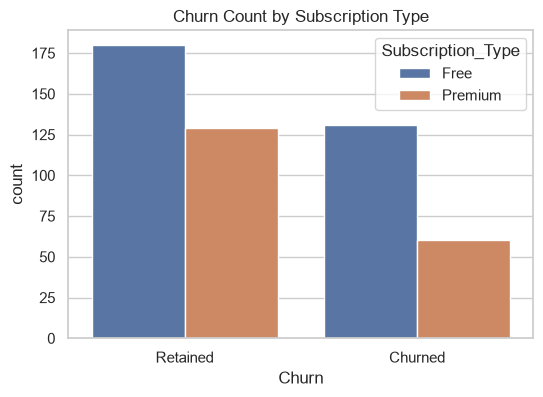

In [12]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn', hue='Subscription_Type')
plt.title('Churn Count by Subscription Type')
plt.show()

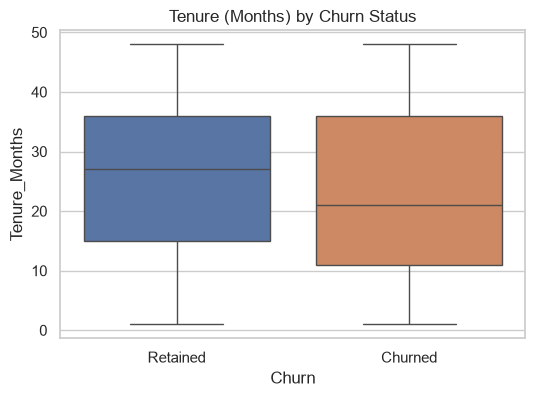

In [13]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x='Churn', y='Tenure_Months', hue='Churn', legend=False)
plt.title('Tenure (Months) by Churn Status')
plt.show()